In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv("planets_300.csv")
x = np.log(data[["a_AU", "M_star_solar"]])
y = np.log(data["T_years"])

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0) # wont change the predictions everytime


In [ ]:
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [ ]:
y_predicted = model.predict(x_test)

In [ ]:
baseline = np.full(len(y_test), np.mean(y_train))

In [ ]:
rmse = lambda p: np.sqrt(mean_squared_error(y_test, p))

In [ ]:
rmse_m = rmse(y_predicted)
rmse_b = rmse(baseline)
r_score = r2_score(y_test, y_predicted)

In [ ]:
Xtr, ytr = x_train.values, y_train.values
Xte, yte = x_test.values,  y_test.values

def predict(X, w, b):
    return X @ w + b

def mse(X, y, w, b):
    return np.mean((predict(X, w, b) - y) ** 2)

def gradient(X, y, w, b):
    err = predict(X, w, b) - y
    dw = 2 * X.T @ err / len(y)     # d(MSE)/dw
    db = 2 * np.mean(err)           # d(MSE)/db
    return dw, db

In [ ]:
np.random.seed(42)

# Initial: weights ~ small random normal (N(0, 0.01^2)), bias = 0.
# small, so we start near the "predict ~0" solution instead of a large arbitrary point
# random (not all zero), so the init is not a hand-picked special case
# bias needs no randomness: the weights already differ, and bias just shifts the output
w = np.random.randn(2) * 0.01
b = 0.0

lr = 0.02
epochs = 1000

train_rmse_hist, test_rmse_hist = [], []
for epoch in range(epochs):
    dw, db = gradient(Xtr, ytr, w, b)
    w = w - lr * dw
    b = b - lr * db
    train_rmse_hist.append(np.sqrt(mse(Xtr, ytr, w, b)))
    test_rmse_hist.append(np.sqrt(mse(Xte, yte, w, b)))

y_pred_gd = predict(Xte, w, b)
rmse_gd = rmse(y_pred_gd)
r2_gd = r2_score(y_test, y_pred_gd)

In [ ]:
print("  coef (log a, log M):", model.coef_, " intercept:", model.intercept_)
print("  model RMSE:", rmse(y_predicted), " baseline RMSE:", rmse(baseline))
print("  model R2:", r2_score(y_test, y_predicted))

  coef (log a, log M): [ 1.5006282  -0.50501103]  intercept: -0.004534282861803796
  model RMSE: 0.03209486900630599  baseline RMSE: 1.3557607816273396
  model R2: 0.9994384950780175


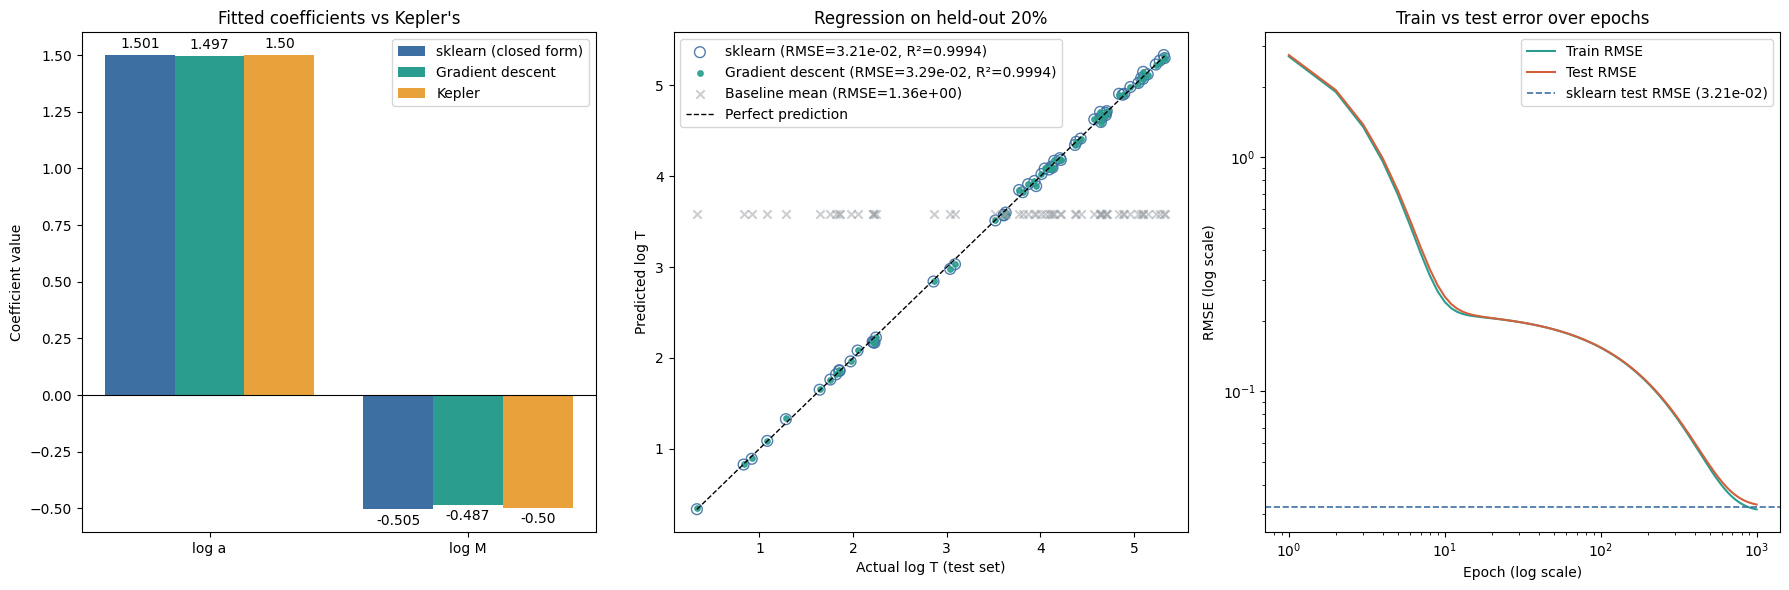

In [ ]:

C_SK     = "#3E6FA3"   # sklearn: steel blue
C_GD     = "#2A9D8F"   # gradient descent: teal
C_KEPLER = "#E9A23B"   # Kepler: amber
C_BASE   = "#9AA0A6"   # baseline: gray
C_TEST   = "#D1603D"   # test curve: terracotta

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
kepler = 1.5, -0.5


ax = axes[0]
labels = ["log a", "log M"]
x = np.arange(len(labels))
w_ = 0.27
b1 = ax.bar(x - w_, model.coef_, w_, label="sklearn (closed form)", color=C_SK)
b3 = ax.bar(x,      w,           w_, label="Gradient descent",      color=C_GD)
b2 = ax.bar(x + w_, kepler,      w_, label="Kepler",                color=C_KEPLER)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Coefficient value")
ax.set_title("Fitted coefficients vs Kepler's")
ax.bar_label(b1, fmt="%.3f", padding=3)
ax.bar_label(b3, fmt="%.3f", padding=3)
ax.bar_label(b2, fmt="%.2f", padding=3)
ax.legend()


ax = axes[1]
ax.scatter(y_test, y_predicted, label=f"sklearn (RMSE={rmse_m:.2e}, R²={r_score:.4f})",
           facecolors="none", edgecolors=C_SK, s=60, alpha=0.9)
ax.scatter(y_test, y_pred_gd, label=f"Gradient descent (RMSE={rmse_gd:.2e}, R²={r2_gd:.4f})",
           color=C_GD, s=15, alpha=0.9)
ax.scatter(y_test, baseline, label=f"Baseline mean (RMSE={rmse_b:.2e})",
           color=C_BASE, alpha=0.5, marker="x")
lo, hi = y_test.min(), y_test.max()
ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="Perfect prediction")
ax.set_xlabel("Actual log T (test set)")
ax.set_ylabel("Predicted log T")
ax.set_title("Regression on held-out 20%")
ax.legend()


ax = axes[2]
ep = np.arange(1, epochs + 1)
ax.plot(ep, train_rmse_hist, label="Train RMSE", color=C_GD)
ax.plot(ep, test_rmse_hist,  label="Test RMSE",  color=C_TEST)
ax.axhline(rmse_m, color=C_SK, ls="--", lw=1.2, label=f"sklearn test RMSE ({rmse_m:.2e})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Epoch (log scale)")
ax.set_ylabel("RMSE (log scale)")
ax.set_title("Train vs test error over epochs")
ax.legend()

plt.tight_layout()
plt.savefig("part3_results.png", dpi=150)
plt.show()